In [ ]:
"""
Relative Niño 3.4 index for CMIP6 storyline analysis.

Computes both the conventional (absolute) and the relative Niño 3.4 index,
where relative = Niño3.4 SST - tropical-mean (20S-20N) SST.

The relative index removes uniform tropical warming -- which does not drive
anomalous deep convection, because the convective threshold rises with the
tropical mean state -- while retaining changes in the zonal SST gradient,
which do project onto the PSA wave train and hence onto Antarctic moisture
transport. Any residual trend in the relative index is therefore physical and
may legitimately contribute to the SMB trend, unlike a linearly detrended
index which is trendless by construction.

Reference for the relative index: van Oldenborgh et al. (2021), ERL,
"Defining El Nino indices in a warming climate".
"""

import glob
import numpy as np
import xarray as xr
from scipy import stats

# ── configuration ────────────────────────────────────────────────────────────
# NOTE: glob historical AND ssp files together so the base period exists.
FILES = sorted(
    glob.glob(r"D:\PolarRESHackthon\DataNew\TOS\MPI\*.nc")
    + glob.glob(r"D:\PolarRESHackthon\DataNew\TOS\MPI\*.nc")
)
AREA_FILE = None   # optional: path to an areacello Ofx file, or None
BASE_START, BASE_END = "1985-01-01", "2014-12-31"   # fixed climatology base
RUNMEAN = 5                                          # months
OUT_CSV = r"D:\PolarRESHackthon\DataNew\TOS\MPI\nino34_indices.csv"

# ── load ─────────────────────────────────────────────────────────────────────
ds = xr.open_mfdataset(
    FILES,
    combine="nested",
    concat_dim="time",
    join="override",
    data_vars="minimal",
    coords="minimal",
    compat="override",
)
_, uniq = np.unique(ds.time, return_index=True)
ds = ds.isel(time=np.sort(uniq)).sortby("time")
ds = ds.resample(time="MS").mean()      # 
tos = ds["tos"]
if tos.attrs.get("units", "").strip().lower() in ("k", "kelvin"):
    tos = tos - 273.15

lat, lon = ds["latitude"], ds["longitude"]
SPATIAL = [d for d in tos.dims if d != "time"]

# ── weights: cell areas, with graceful fallbacks ─────────────────────────────
EARTH_R = 6.371e6  # m


def cell_area(ds, lat):
    """Grid-cell area, in decreasing order of accuracy.

    1. areacello from a separate Ofx file (exact).
    2. Derived from the cell vertices carried inside the tos file itself.
       Near-exact in the tropics, where the POP displaced-pole grid is
       essentially lat-lon aligned (the pole sits over the Arctic).
    3. cos(lat) (approximate: ignores the meridional refinement of the POP
       grid near the equator, so it over-weights the equatorial rows).
    """
    if AREA_FILE:
        try:
            print("weights: areacello")
            return xr.open_dataset(AREA_FILE)["areacello"]
        except (FileNotFoundError, OSError, KeyError):
            pass

    vlat_name = next((n for n in ("vertices_latitude", "lat_vertices",
                                  "lat_bnds") if n in ds), None)
    vlon_name = next((n for n in ("vertices_longitude", "lon_vertices",
                                  "lon_bnds") if n in ds), None)
    if vlat_name and vlon_name:
        vlat, vlon = ds[vlat_name], ds[vlon_name]
        vdim = [d for d in vlat.dims if d not in lat.dims][0]
        lat_hi, lat_lo = vlat.max(vdim), vlat.min(vdim)
        dlon = vlon.max(vdim) - vlon.min(vdim)
        dlon = xr.where(dlon > 180, 360 - dlon, dlon)   # dateline wrap
        print(f"weights: derived from {vlat_name}")
        return (EARTH_R ** 2 * np.deg2rad(dlon)
                * (np.sin(np.deg2rad(lat_hi)) - np.sin(np.deg2rad(lat_lo))))

    print("weights: cos(lat) fallback -- see the sanity check below")
    return np.cos(np.deg2rad(lat))


area = cell_area(ds, lat).fillna(0.0)

# ── region masks ─────────────────────────────────────────────────────────────
lon360 = lon % 360
nino34_mask = (lat >= -5) & (lat <= 5) & (lon360 >= 190) & (lon360 <= 240)
tropics_mask = (lat >= -20) & (lat <= 20)


def wmean(da, mask):
    """Area-weighted spatial mean.

    .weighted().mean() ignores NaN in the data and renormalises the weights
    over valid cells -- unlike (da * w).sum(), which counts masked land as
    zero while still dividing by its weight.
    """
    return da.where(mask).weighted(area).mean(dim=SPATIAL)


nino34_sst = wmean(tos, nino34_mask).compute()
tropics_sst = wmean(tos, tropics_mask).compute()

# ── anomalies relative to a FIXED base period ────────────────────────────────
def anomalise(series, name):
    base = series.sel(time=slice(BASE_START, BASE_END))
    if base.time.size < 12 * 20:
        print(f"WARNING [{name}]: base period covers only {base.time.size} "
              f"months -- using full record instead. Historical and projection "
              f"indices will not be directly comparable.")
        base = series
    clim = base.groupby("time.month").mean("time")
    return series.groupby("time.month") - clim


nino34_abs = anomalise(nino34_sst, "absolute")
nino34_rel = anomalise(nino34_sst - tropics_sst, "relative")

# ── running mean (no partial windows at the edges) ───────────────────────────
kw = dict(time=RUNMEAN, center=True, min_periods=RUNMEAN)
idx_abs = nino34_abs.rolling(**kw).mean()
idx_rel = nino34_rel.rolling(**kw).mean()

# ── standardise by the BASE-PERIOD sigma, not the full-record sigma ──────────
# Using the full-record sigma would absorb any change in ENSO amplitude into
# the normalisation and hide exactly the signal you want to test for.
sigma_base = float(idx_rel.sel(time=slice(BASE_START, BASE_END)).std())
idx_rel_std = idx_rel / sigma_base
print(f"base-period sigma (relative index): {sigma_base:.3f} degC")

# ── diagnostics ──────────────────────────────────────────────────────────────
tyear = (idx_abs["time.year"] + (idx_abs["time.month"] - 1) / 12.0).values


def trend(series, label):
    y = series.values
    ok = np.isfinite(y)
    res = stats.linregress(tyear[ok], y[ok])
    print(f"{label:>28}: {res.slope * 10:+.4f} degC/decade "
          f"(p = {res.pvalue:.3g})")
    return res


# Does the weighting choice actually matter? Compare against plain cos(lat).
cos_w = np.cos(np.deg2rad(lat)).fillna(0.0)
alt = tos.where(nino34_mask).weighted(cos_w).mean(dim=SPATIAL).compute()
r_w = float(xr.corr(nino34_sst - nino34_sst.mean(), alt - alt.mean()))
print(f"\ncorr(area-weighted, cos-lat-weighted) Nino3.4 = {r_w:.5f}")
print("  -> if r > 0.999 the two differ by a near-constant rescaling, which "
      "leaves variance-explained percentages untouched.")

print("\n── linear trends over the full record ──")
trend(idx_abs, "absolute Nino3.4")
trend(idx_rel, "relative Nino3.4")
trend(tropics_sst - tropics_sst.mean(), "tropical mean SST")

# 30-year sliding standard deviation: amplitude change test
std30 = idx_rel.rolling(time=360, center=True, min_periods=300).std()
print("\n── 30-yr sliding sigma of the relative index ──")
print(f"  early (first valid): {float(std30.dropna('time')[0]):.3f} degC")
print(f"  late  (last valid) : {float(std30.dropna('time')[-1]):.3f} degC")
print("  -> bootstrap this before claiming any change is/isn't significant; "
        "~75 yr gives only ~20-25 ENSO cycles.")

# ── save ─────────────────────────────────────────────────────────────────────
out = xr.Dataset({
    "nino34_absolute": idx_abs,
    "nino34_relative": idx_rel,
    "nino34_relative_std": idx_rel_std,
    "tropical_mean_sst": tropics_sst,
    "sliding_sigma_30yr": std30,
}).to_dataframe()
out.to_csv(OUT_CSV)
print(f"\nSaved -> {OUT_CSV}")

weights: derived from vertices_latitude


standard deviation (1985-2014):
  OBS           : 0.707 degC
  MPI-ESM1-2-LR : 0.603 degC (-> 0.642 degC in 2080-2099)
  CESM2         : 1.003 degC (-> 1.092 degC in 2080-2099)


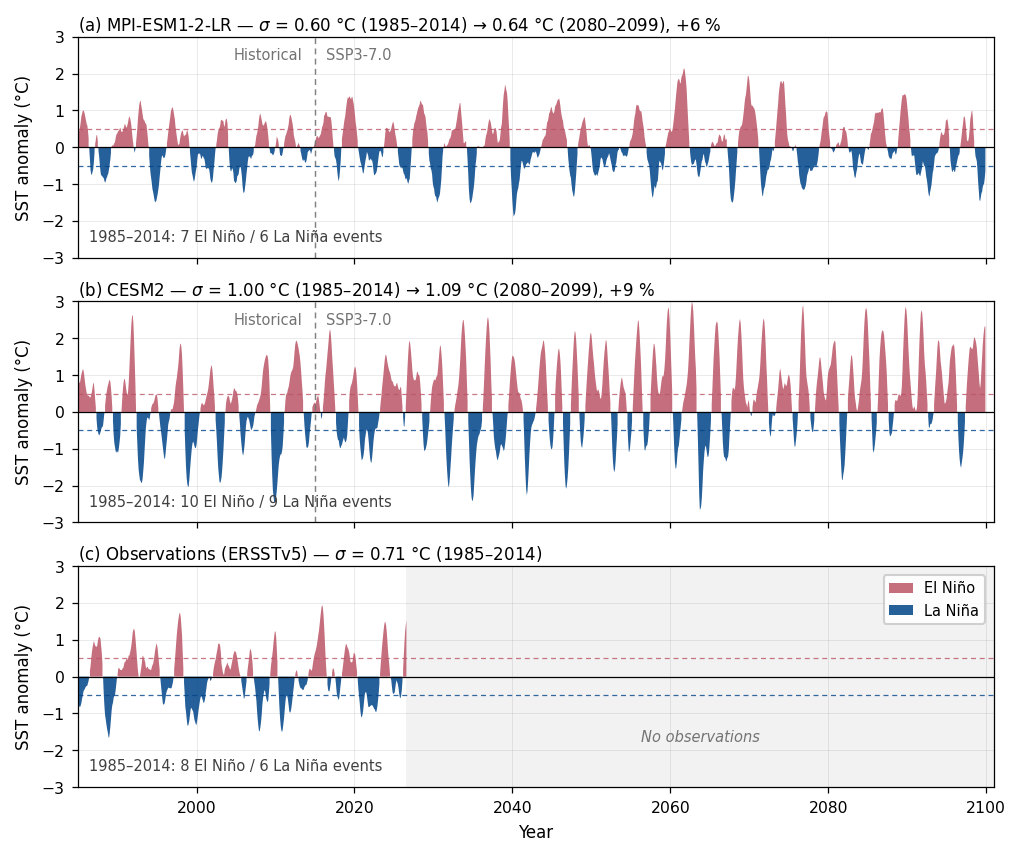

In [5]:
"""
Nino 3.4 index figure - MPI-ESM1-2-LR, CESM2 and ERSSTv5 observations.
"""

from __future__ import annotations

import re
import urllib.request
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import signal

# ---------------------------------------------------------------------------
# Configuration
# ---------------------------------------------------------------------------
DATA_DIR = Path(r"D:\PolarRESHackthon\DataNew\ENSO")
OUT_DIRS = [Path(r"D:\PolarRESHackthon\Paper"), DATA_DIR]
STEM = "fig_nino34_MPI_CESM2"

PATHS = {
    "MPI-ESM1-2-LR": DATA_DIR / "rel_nino34_indices_MPI.csv",
    "CESM2": DATA_DIR / "rel_nino34_indices_CESM2.csv",
}

TIME_RANGE = ("1985", "2099")
HIST_RANGE = ("1985", "2014")   # matched window for the model/obs comparison
FUT_RANGE = ("2080", "2099")    # end-of-century window
CLIM = ("1985", "2014")         # must match the base period of the model index
OBS_URL = "https://psl.noaa.gov/data/correlation/nina34.anom.data"

SPLIT = pd.Timestamp("2015-01-01")
XLIM = (pd.Timestamp("1985-01-01"), pd.Timestamp("2100-12-31"))
YLIM = (-3, 3)                  # use (-4, 4) with YTICKS (-4,-2,0,2,4) to match SAM exactly
YTICKS = (-3, -2, -1, 0, 1, 2, 3)

RUNMEAN_YEARS = 30              # window for the running standard deviation
DETREND_OBS = True              # linear detrend of the observed anomaly

C_POS = "#BB5566"               # El Nino  (same red as the SAM figure)
C_NEG = "#004488"               # La Nina  (same blue as the SAM figure)
C_GREY = "0.45"

# ---------------------------------------------------------------------------
# Copernicus / WCD style
# ---------------------------------------------------------------------------
WCD_STYLE = {
    # 170 mm = 6.69 in double-column width; nothing is scaled at typesetting,
    # so the font sizes below are the sizes that appear on the printed page.
    "figure.figsize": (6.69, 5.6),
    "figure.dpi": 150,
    "savefig.dpi": 600,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.02,
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "Nimbus Sans", "DejaVu Sans"],
    "font.size": 8,
    "axes.titlesize": 8,
    "axes.labelsize": 8,
    "xtick.labelsize": 7.5,
    "ytick.labelsize": 7.5,
    "legend.fontsize": 7,
    "axes.linewidth": 0.6,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    "xtick.major.size": 3,
    "ytick.major.size": 3,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "lines.linewidth": 0.9,
    "grid.linewidth": 0.4,
    "grid.alpha": 0.3,
    "legend.frameon": True,
    "legend.framealpha": 0.9,
    "legend.edgecolor": "0.8",
    "legend.borderpad": 0.4,
    "legend.handlelength": 1.6,
    "pdf.fonttype": 42,          # embed TrueType, not Type-3 subsets
    "ps.fonttype": 42,
    "pdf.compression": 6,
    "axes.unicode_minus": True,
}


# ---------------------------------------------------------------------------
# Data
# ---------------------------------------------------------------------------
def load_models(paths=PATHS, time_range=TIME_RANGE) -> dict[str, pd.Series]:
    """Load the relative Nino 3.4 index for each model.

    The *relative* index (Nino 3.4 SST minus tropical-mean SST) already removes
    the mean warming signal, so no additional linear detrend is applied here.
    """
    out = {}
    for model, path in paths.items():
        df = pd.read_csv(path)
        df["time"] = pd.to_datetime(df["time"])
        df = df.set_index("time").sort_index()
        out[model] = df.loc[time_range[0]:time_range[1], "nino34_relative"].astype(float)
    return out


def load_obs_nino34(url=OBS_URL, clim=CLIM, window=5, start=TIME_RANGE[0],
                    detrend=DETREND_OBS) -> pd.Series:
    """PSL ERSSTv5 Nino 3.4 monthly anomaly, processed like the model index:
    re-baselined to `clim`, 5-month centred mean, then linearly detrended over
    the plotted window so it is comparable with the relative model index."""
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    txt = urllib.request.urlopen(req, timeout=30).read().decode("utf-8", "replace")

    rows = {}
    for line in txt.splitlines():
        t = line.split()
        if not t or not re.fullmatch(r"\d{4}", t[0]):
            continue
        vals = []
        for tok in t[1:13]:
            try:
                vals.append(float(tok))
            except ValueError:
                vals.append(np.nan)
        rows[int(t[0])] = (vals + [np.nan] * 12)[:12]

    grid = pd.DataFrame.from_dict(rows, orient="index", columns=range(1, 13)).sort_index()
    s = grid.stack(future_stack=True)
    s = pd.Series(
        s.to_numpy(),
        index=pd.to_datetime([f"{y:04d}-{m:02d}-01" for y, m in s.index]),
    ).sort_index().replace([-99.99, -99.9, -999.0], np.nan)

    base = s[clim[0]:clim[1]]
    s = s - s.index.month.map(base.groupby(base.index.month).mean())
    s = s.rolling(window, center=True, min_periods=3).mean()

    # Slice first, then detrend, so the trend is removed over the same window
    # that is plotted and used for the variance comparison.
    out = s[start:].dropna()
    if detrend:
        out = pd.Series(signal.detrend(out.values), index=out.index)
    return out.rename("obs")


# ---------------------------------------------------------------------------
# Statistics
# ---------------------------------------------------------------------------
def count_events(s: pd.Series, threshold=0.5, min_months=5, warm=True) -> int:
    """Number of ONI-style events: >= 5 consecutive months beyond +-0.5 degC."""
    mask = (s >= threshold) if warm else (s <= -threshold)
    runs = (mask != mask.shift()).cumsum()[mask]
    return int((runs.value_counts() >= min_months).sum())


def running_std(s: pd.Series, years=RUNMEAN_YEARS) -> pd.Series:
    return s.rolling(years * 12, center=True, min_periods=years * 6).std()


def window_std(s: pd.Series, rng) -> float:
    return float(s[rng[0]:rng[1]].std())


# ---------------------------------------------------------------------------
# Figure
# ---------------------------------------------------------------------------
def make_figure(models: dict[str, pd.Series], obs: pd.Series, suptitle: str | None = None):
    """Three stacked panels, styled to match the SAM trend figure."""
    panels = [(name, s, True) for name, s in models.items()]
    panels.append(("Observations (ERSSTv5)", obs, False))

    with mpl.rc_context(WCD_STYLE):
        fig, axes = plt.subplots(len(panels), 1, sharex=True, sharey=True,
                                 constrained_layout=True)

        for k, (ax, (name, s, is_model)) in enumerate(zip(axes, panels)):
            letter = "abcdefg"[k]

            ax.fill_between(s.index, s, 0, where=s >= 0, color=C_POS,
                            linewidth=0, alpha=0.85, label="El Ni\u00f1o")
            ax.fill_between(s.index, s, 0, where=s < 0, color=C_NEG,
                            linewidth=0, alpha=0.85, label="La Ni\u00f1a")

            rs = running_std(s)
            #ax.plot(rs.index, rs, color="k", linewidth=1.0,                    label=f"{RUNMEAN_YEARS}-year running $\\sigma$")

            ax.axhline(0, color="k", linewidth=0.6)
            ax.axhline(0.5, color=C_POS, linewidth=0.6, linestyle=(0, (4, 3)), alpha=0.8)
            ax.axhline(-0.5, color=C_NEG, linewidth=0.6, linestyle=(0, (4, 3)), alpha=0.8)

            ax.set_ylim(*YLIM)
            ax.set_yticks(list(YTICKS))
            ax.set_ylabel("SST anomaly (\u00b0C)")
            ax.grid(True, linewidth=0.4, alpha=0.3)
            ax.set_axisbelow(True)

            # --- headline statistic in the panel title (SAM figure convention)
            sd_hist = window_std(s, HIST_RANGE)
            if is_model:
                sd_fut = window_std(s, FUT_RANGE)
                pct = 100 * (sd_fut / sd_hist - 1)
                head = (f"$\\sigma$ = {sd_hist:.2f} \u00b0C ({HIST_RANGE[0]}\u2013{HIST_RANGE[1]}) "
                        f"\u2192 {sd_fut:.2f} \u00b0C ({FUT_RANGE[0]}\u2013{FUT_RANGE[1]}), "
                        f"{pct:+.0f} %").replace("-", "\u2212")
            else:
                head = (f"$\\sigma$ = {sd_hist:.2f} \u00b0C "
                        f"({HIST_RANGE[0]}\u2013{HIST_RANGE[1]})")
            ax.set_title(f"({letter}) {name} \u2014 {head}", loc="left", pad=3)

            # --- secondary statistic inside the axes (Theil-Sen slot)
            n_pos = count_events(s[HIST_RANGE[0]:HIST_RANGE[1]], warm=True)
            n_neg = count_events(s[HIST_RANGE[0]:HIST_RANGE[1]], warm=False)
            ax.text(0.012, 0.06,
                    f"{HIST_RANGE[0]}\u2013{HIST_RANGE[1]}: "
                    f"{n_pos} El Ni\u00f1o / {n_neg} La Ni\u00f1a events",
                    transform=ax.transAxes, fontsize=7, color="0.25",
                    ha="left", va="bottom")

            # --- scenario split (models) or end of record (observations)
            if is_model:
                ax.axvline(SPLIT, color=C_GREY, linewidth=0.7,
                           linestyle=(0, (4, 3)), alpha=0.9)
                ax.text(pd.Timestamp("2013-06-01"), YLIM[1] * 0.90, "Historical",
                        fontsize=7, color=C_GREY, ha="right", va="top")
                ax.text(pd.Timestamp("2016-06-01"), YLIM[1] * 0.90, "SSP3-7.0",
                        fontsize=7, color=C_GREY, ha="left", va="top")
            else:
                ax.axvspan(s.index.max(), XLIM[1], color="0.5", alpha=0.10, linewidth=0)
                mid = s.index.max() + (XLIM[1] - s.index.max()) / 2
                ax.text(mid, YLIM[0] * 0.55, "No observations",
                        fontsize=7, color=C_GREY, style="italic",
                        ha="center", va="center")

        axes[-1].set_xlabel("Year")
        axes[-1].set_xlim(*XLIM)
        axes[-1].set_xticks([pd.Timestamp(f"{y}-01-01") for y in range(2000, 2101, 20)])
        axes[-1].set_xticklabels([str(y) for y in range(2000, 2101, 20)])

        # single legend, in the bottom panel, placed in the empty post-record
        # space so it never covers data (the SAM figure also legends panel c)
        axes[-1].legend(loc="upper right", ncol=1, borderaxespad=0.6)

        if suptitle:
            fig.suptitle(suptitle, fontsize=8.5, fontweight="bold")

    return fig, axes


def save(fig, stem=STEM, out_dirs=OUT_DIRS):
    for d in out_dirs:
        d = Path(d)
        d.mkdir(parents=True, exist_ok=True)
        fig.savefig(d / f"{stem}.pdf")   # vector - submit this one
        fig.savefig(d / f"{stem}.png", dpi=600)


# ---------------------------------------------------------------------------
def main():
    models = load_models()
    obs = load_obs_nino34()

    print(f"standard deviation ({HIST_RANGE[0]}-{HIST_RANGE[1]}):")
    print(f"  {'OBS':<14}: {window_std(obs, HIST_RANGE):.3f} degC")
    for name, s in models.items():
        print(f"  {name:<14}: {window_std(s, HIST_RANGE):.3f} degC "
              f"(-> {window_std(s, FUT_RANGE):.3f} degC in "
              f"{FUT_RANGE[0]}-{FUT_RANGE[1]})")

    # Copernicus prefers the title in the caption, so no suptitle by default.
    fig, _ = make_figure(models, obs, suptitle=None)
    save(fig)
    plt.show()


if __name__ == "__main__":
    main()

In [6]:
"""
ENSO intensity analysis - rolling variability, wavelet power, ENSO-band power.

Same three-panel layout, colours and content as the original MPI/CESM2 scripts;
only the presentation is changed for Weather and Climate Dynamics (Copernicus):
170 mm width, 8 pt sans-serif, vector PDF with embedded Type-42 fonts, and the
filled contours rasterised so the PDF stays small while text and lines stay
vector.

The two original scripts differed only in the input path, the title and the
output name, so they are merged into one loop over MODELS.
"""

from __future__ import annotations

from pathlib import Path

import matplotlib as mpl
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pycwt as wavelet
import pymannkendall as mk

# ---------------------------------------------------------------------------
# Configuration
# ---------------------------------------------------------------------------
DATA_DIR = Path(r"D:\PolarRESHackthon\DataNew\ENSO")
OUT_DIRS = [Path(r"D:\PolarRESHackthon\Paper"), DATA_DIR]

MODELS = {
    "MPI-ESM1-2-LR": {"file": "rel_nino34_indices_MPI.csv", "stem": "fig_enso_intensity_MPI"},
    "CESM2": {"file": "rel_nino34_indices_CESM2.csv", "stem": "fig_enso_intensity_CESM2"},
}

TIME_RANGE = ("1985", "2099")
WINDOW_YEARS = 30              # rolling-sigma and band-power smoothing window
ENSO_BAND = (2, 7)             # years
POWER_VMAX = 100.0             # fixed across models so panels are comparable
BANDPOWER_YLIM = (0, 50)
XTICKS = list(range(2000, 2101, 20))

C_STD = "#e08214"              # rolling sigma  (unchanged)
C_TREND = "firebrick"          # Theil-Sen line (unchanged)
C_BAND = "#542788"             # ENSO-band power (unchanged)
CMAP = "YlOrRd"                # unchanged

# ---------------------------------------------------------------------------
# Copernicus / WCD style (identical to the Nino 3.4 figure script)
# ---------------------------------------------------------------------------
WCD_STYLE = {
    "figure.figsize": (6.69, 6.3),   # 170 mm double-column width
    "figure.dpi": 150,
    "savefig.dpi": 600,              # applies to the rasterised contour layer
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.02,
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "Nimbus Sans", "DejaVu Sans"],
    "font.size": 8,
    "axes.titlesize": 8,
    "axes.labelsize": 8,
    "xtick.labelsize": 7.5,
    "ytick.labelsize": 7.5,
    "legend.fontsize": 7,
    "axes.linewidth": 0.6,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    "xtick.major.size": 3,
    "ytick.major.size": 3,
    "lines.linewidth": 0.9,
    "grid.linewidth": 0.4,
    "grid.alpha": 0.3,
    "legend.frameon": True,
    "legend.framealpha": 0.9,
    "legend.edgecolor": "0.8",
    "legend.borderpad": 0.4,
    "legend.handlelength": 1.8,
    "hatch.linewidth": 0.4,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "pdf.compression": 6,
    "axes.unicode_minus": True,
}


# ---------------------------------------------------------------------------
# Analysis (unchanged from the original scripts)
# ---------------------------------------------------------------------------
def compute_ar1(x: np.ndarray) -> float:
    x = x - x.mean()
    return np.dot(x[:-1], x[1:]) / (len(x) - 1) / (np.dot(x, x) / len(x))


def analyse(path: Path, time_range=TIME_RANGE, window_years=WINDOW_YEARS,
            band=ENSO_BAND) -> dict:
    df = pd.read_csv(path)
    df["time"] = pd.to_datetime(df["time"])
    df = df.set_index("time").sort_index()
    df = df[time_range[0]:time_range[1]]

    # The relative index already removes the mean warming signal, so no extra
    # linear detrend is applied (matches the original scripts).
    s = df["nino34_relative"].astype(float)
    sst = s.to_numpy()
    time = s.index
    years = time.year + time.month / 12

    # -- 1. rolling standard deviation
    rolling_std = s.rolling(window=window_years * 12, center=True).std()

    # -- 2. Mann-Kendall on the rolling sigma
    mk_res = mk.hamed_rao_modification_test(rolling_std.dropna())

    # -- 3. wavelet
    dt = 1 / 12
    std_sst = sst.std()
    sst_norm = sst / std_sst

    mother = wavelet.Morlet(6)
    wave, scales, freqs, coi, _, _ = wavelet.cwt(sst_norm, dt, wavelet=mother)
    power = np.abs(wave) ** 2 * std_sst ** 2
    periods = 1 / freqs

    alpha = compute_ar1(sst_norm)
    signif, _ = wavelet.significance(
        std_sst ** 2, dt, scales,
        sigma_test=0, significance_level=0.95,
        alpha=alpha, wavelet=mother,
    )
    sig95 = power / signif[:, None]

    mask = (periods >= band[0]) & (periods <= band[1])
    enso_periods = periods[mask]
    power_enso = power[mask, :]
    sig95_enso = sig95[mask, :]

    coi_valid = enso_periods[:, None] <= coi[None, :]
    enso_power = np.where(coi_valid, power_enso, np.nan).mean(axis=0)

    return dict(series=s, time=time, years=years, rolling_std=rolling_std,
                mk=mk_res, enso_periods=enso_periods, power_enso=power_enso,
                sig95_enso=sig95_enso, coi=coi, enso_power=enso_power,
                alpha=alpha)


# ---------------------------------------------------------------------------
# Figure
# ---------------------------------------------------------------------------
def make_figure(res: dict, model: str, suptitle: str | None = None):
    time, years = res["time"], res["years"]
    rolling_std, mk_res = res["rolling_std"], res["mk"]
    enso_periods, coi = res["enso_periods"], res["coi"]

    xlim_dt = (time[0], time[-1])
    xlim_yr = (years[0], years[-1])
    xticks_dt = [pd.Timestamp(f"{y}-01-01") for y in XTICKS]

    with mpl.rc_context(WCD_STYLE):
        fig = plt.figure()
        gs = gridspec.GridSpec(3, 2, figure=fig,
                               height_ratios=[1, 1.6, 1],
                               width_ratios=[1, 0.02],
                               hspace=0.42, wspace=0.04)

        # ---------------- Panel (a): rolling sigma --------------------------
        ax1 = fig.add_subplot(gs[0, 0])
        ax1_cb = fig.add_subplot(gs[0, 1])
        ax1_cb.set_visible(False)

        ax1.plot(time, rolling_std, color=C_STD, linewidth=1.3,
                 label=f"{WINDOW_YEARS}-year rolling $\\sigma$")
        ax1.axhline(rolling_std.mean(), color="k", linewidth=0.7,
                    linestyle=(0, (4, 3)),
                    label=f"Mean = {rolling_std.mean():.2f} \u00b0C")

        # Theil-Sen line from the Mann-Kendall result itself. The original
        # plotted an ordinary least-squares fit under a "Sen's slope" label.
        valid = rolling_std.dropna()
        x_num = np.arange(len(valid))
        sen_line = mk_res.intercept + mk_res.slope * x_num
        ax1.plot(valid.index, sen_line, color=C_TREND, linewidth=1.1,
                 linestyle=(0, (4, 3)),
                 label=(f"Theil\u2013Sen: {mk_res.slope * 120:+.3f} "
                        f"\u00b0C decade$^{{-1}}$").replace("-", "\u2212"))

        ax1.set_title(
            f"(a) {WINDOW_YEARS}-year rolling standard deviation \u2014 "
            f"Mann\u2013Kendall test: {mk_res.trend} "
            f"(p = {mk_res.p:.3f}, $\\tau$ = {mk_res.Tau:.2f})",
            loc="left", pad=3)
        ax1.set_ylabel("$\\sigma$ (\u00b0C)")
        ax1.legend(loc="upper left", borderaxespad=0.4)
        ax1.grid(True)
        ax1.set_axisbelow(True)
        ax1.set_xlim(*xlim_dt)
        ax1.set_xticks(xticks_dt)
        ax1.set_xticklabels([str(y) for y in XTICKS])

        # ---------------- Panel (b): wavelet power --------------------------
        ax2 = fig.add_subplot(gs[1, 0])
        ax2_cb = fig.add_subplot(gs[1, 1])

        t_grid, p_grid = np.meshgrid(years, enso_periods)
        levels = np.linspace(0, POWER_VMAX, 50)
        # everything drawn below zorder 0 is rasterised at savefig.dpi; this
        # keeps the 50-level fill compact in the PDF and avoids the thin white
        # seams that vector contour fills show in some viewers, while the
        # contours, hatching, text and axes stay vector
        ax2.set_rasterization_zorder(0)
        cf = ax2.contourf(t_grid, p_grid, res["power_enso"], levels=levels,
                          cmap=CMAP, extend="max", vmin=0, vmax=POWER_VMAX,
                          zorder=-5)

        ax2.contour(t_grid, p_grid, res["sig95_enso"], levels=[1.0],
                    colors="k", linewidths=0.6, zorder=2)

        ax2.fill_between(years, coi, enso_periods.max(),
                         where=coi < enso_periods.max(),
                         color="none", hatch="//", edgecolor="0.55",
                         linewidth=0.0, label="Cone of influence", zorder=3)
        ax2.plot(years, np.clip(coi, enso_periods.min(), enso_periods.max()),
                 color="0.55", linewidth=0.7, linestyle=(0, (4, 3)), zorder=3)

        cb = fig.colorbar(cf, cax=ax2_cb,
                          ticks=np.arange(0, POWER_VMAX + 1, 20))
        cb.set_label("Power (\u00b0C$^2$)", fontsize=8)
        cb.ax.tick_params(labelsize=7.5, width=0.6, length=3)
        cb.outline.set_linewidth(0.6)
        if cb.solids is not None:
            cb.solids.set_rasterized(True)

        ax2.set_ylim(enso_periods.min(), enso_periods.max())
        ax2.set_yscale("log")
        ax2.set_yticks([2, 3, 4, 5, 6, 7])
        ax2.set_yticklabels(["2", "3", "4", "5", "6", "7"])
        ax2.set_ylabel("Period (years)")
        ax2.set_title(
            f"(b) Wavelet power spectrum, ENSO band ({ENSO_BAND[0]}\u2013"
            f"{ENSO_BAND[1]} years)", loc="left", pad=3)
        ax2.legend(loc="upper left", borderaxespad=0.4)
        ax2.set_xlim(*xlim_yr)
        ax2.set_xticks(XTICKS)

        # ---------------- Panel (c): ENSO-band power ------------------------
        ax3 = fig.add_subplot(gs[2, 0])
        ax3_cb = fig.add_subplot(gs[2, 1])
        ax3_cb.set_visible(False)

        p = np.clip(res["enso_power"], 0, np.nanpercentile(res["enso_power"], 99))
        band_power = pd.Series(p, index=time)
        smoothed = band_power.rolling(window=WINDOW_YEARS * 12, center=True).mean()

        ax3.fill_between(time, p, color=C_BAND, alpha=0.20, linewidth=0)
        ax3.plot(time, p, color=C_BAND, linewidth=0.5, alpha=0.7,
                 label=f"Mean power in ENSO band ({ENSO_BAND[0]}\u2013"
                       f"{ENSO_BAND[1]} years)")
        # the original computed this smoothed series but never drew it
        ax3.plot(smoothed.index, smoothed, color="k", linewidth=1.1,
                 label=f"{WINDOW_YEARS}-year running mean")

        ax3.set_ylabel("Power (\u00b0C$^2$)")
        ax3.set_xlabel("Year")
        ax3.set_title("(c) ENSO-band power over time", loc="left", pad=3)
        ax3.legend(loc="upper left", ncol=2, borderaxespad=0.4)
        ax3.grid(True)
        ax3.set_axisbelow(True)
        ax3.set_xlim(*xlim_dt)
        ax3.set_ylim(*BANDPOWER_YLIM)
        ax3.set_xticks(xticks_dt)
        ax3.set_xticklabels([str(y) for y in XTICKS])

        if suptitle:
            fig.suptitle(suptitle, fontsize=8.5, fontweight="bold")

    return fig


def save(fig, stem: str, out_dirs=OUT_DIRS):
    for d in out_dirs:
        d = Path(d)
        d.mkdir(parents=True, exist_ok=True)
        fig.savefig(d / f"{stem}.pdf")   # vector - submit this one
        fig.savefig(d / f"{stem}.png", dpi=600)


# ---------------------------------------------------------------------------
def main():
    for model, cfg in MODELS.items():
        res = analyse(DATA_DIR / cfg["file"])
        m = res["mk"]
        print(f"{model}: trend = {m.trend} | p = {m.p:.4f} | "
              f"Theil-Sen = {m.slope * 120:+.4f} degC/decade | "
              f"AR(1) = {res['alpha']:.3f}")

        # Copernicus prefers the title in the caption, so no suptitle by default.
        fig = make_figure(res, model, suptitle=None)
        save(fig, cfg["stem"])
        plt.close(fig)


if __name__ == "__main__":
    main()

MPI-ESM1-2-LR: trend = increasing | p = 0.0021 | Theil-Sen = +0.0276 degC/decade | AR(1) = 0.985
CESM2: trend = no trend | p = 0.0686 | Theil-Sen = +0.0235 degC/decade | AR(1) = 0.977
